# Visual Modality: Training & Evaluation (mask-aware)

Sequence model (GRU / LSTM) on the cached `(T, D)` visual features, with a per-frame **validity mask** (`True` = real face observation). With `use_mask=True` the model replaces invalid frames with a learned "missing" embedding and excludes them from pooling. All logic lives in `src/training/visual/`; all settings live in one `VisualConfig`.

| Stage | Class | Module |
|---|---|---|
| Config (EDA + training + `use_mask`) | `VisualConfig` | `visual_config.py` |
| Cached features + masks | `FeatureStore` | `notebooks/eda/visual` |
| Load into arrays | `CachedFeatureLoader`, `FeatureSelector`, `SpeakerParser` | `dataset.py` |
| Speaker-disjoint split | `SpeakerSplitter` | `splits.py` |
| Normalise (valid frames only) + torch dataset | `Standardizer`, `VisualSequenceDataset` | `dataset.py` |
| Model | `RNNClassifier` | `model.py` |
| Training / evaluation | `Trainer`, `Evaluator` | `trainer.py`, `evaluator.py` |
| One run / seed sweep | `Experiment` | `experiment.py` |

In [42]:
import os, sys, dataclasses
import numpy as np
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if project_root not in sys.path:
    sys.path.append(project_root)
os.environ["LIBGL_ALWAYS_SOFTWARE"] = "1"

import pandas as pd
from IPython.display import display

from src.common.constants import OPENFACE_BIN
from src.common.visual_config import VisualConfig
from src.extractors.visual.visual_feature_extractor import VisualFeatureExtractor
from notebooks.eda.visual import (
    HFDatasetLoader, VideoCatalog, OpenFaceTableStore, SceneDetector,
    QualityAuditor, QualityThresholds, FeatureStore,
)
from src.training.visual import (
    CachedFeatureLoader, FeatureSelector, SpeakerParser, SpeakerSplitter,
    Experiment, TrainingPlots, EvalPlots, Evaluator,
)

## Config
One config for everything. `use_mask` is the switch for the masked vs. unmasked comparison.

In [29]:
cfg = VisualConfig(
    data_dir="../data", openface_bin=OPENFACE_BIN, device="cuda",
    # model
    rnn_type="gru",            # "lstm" | "gru"
    hidden_dim=64, num_layers=1, bidirectional=False, pooling="attention",
    # masking
    use_mask=True,             # False = old behaviour (zeroed frames are read as real data)
    # data
    use_quality_gate=True,     # True = only keep videos whose scenes all pass the Stage-3 gate
    include_prefixes=None,     # e.g. ("au_", "gaze_")
    exclude_prefixes=None,     # e.g. ("emo_",) to ablate emotion probabilities
    seed=42,
)
os.makedirs(cfg.output_dir, exist_ok=True)
print(cfg)

VisualConfig(data_dir='../data', hf_repo_id='dandyidk/Multi-Modal-Lie-Detection', hf_folders=('deception', 'truth'), openface_bin='/home/dandy/OpenFace/build/bin/FeatureExtraction', device='cuda', openface_workers=4, scene_method='content', scene_threshold=27.0, scene_min_len=30, scene_frame_skip=2, scene_workers=4, pose_jump_mm=50.0, conf_thresh=0.75, jitter_thresh=20.0, max_dropout_pct=15.0, chunk_length_sec=8.0, overlap_sec=2.0, target_t=200, openface_cache_dir='../data/openface_cache', scene_cache_dir='../data/scene_cache_v2', feature_cache_dir='../data/feature_cache', quality_report_path='../data/openface_quality_report.csv', use_quality_gate=True, include_prefixes=None, exclude_prefixes=None, val_frac=0.15, test_frac=0.15, batch_size=32, use_mask=True, rnn_type='gru', hidden_dim=64, num_layers=1, bidirectional=False, dropout=0.3, pooling='attention', lr=0.001, weight_decay=0.01, epochs=100, patience=14, grad_clip=1.0, class_weighted_loss=True, noise_std=0.05, feature_dropout=0.1,

## Data: cached OpenFace features + masks
Reuses the OpenFace/scene caches. The first run after enabling masks recomputes `feature_cache` once (emotion model), because the mask cache does not exist yet.

In [30]:
MAX_VIDEOS = 9999999

loader = HFDatasetLoader(cfg.hf_repo_id, cfg.data_dir, folders=cfg.hf_folders)
# loader.download()
catalog = VideoCatalog(cfg.data_dir)
meta_df = catalog.build(loader.local_video_paths())
meta_df = meta_df.sample(n=min(MAX_VIDEOS, len(meta_df)), random_state=cfg.seed).reset_index(drop=True)

extractor = VisualFeatureExtractor(openface_bin_path=cfg.openface_bin, device=cfg.device)
tables = OpenFaceTableStore(extractor, cfg.openface_cache_dir, workers=cfg.openface_workers)
tables.ensure(meta_df)
features = FeatureStore(extractor, tables, cfg.feature_cache_dir, target_t=cfg.target_t)
print(features.ensure(meta_df).summary())    # builds feature + mask caches for anything missing

Reading video metadata:   0%|          | 0/1573 [00:00<?, ?it/s]

Invalid model-index. Not loading eval results into CardData.
Invalid model-index. Not loading eval results into CardData.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[openface] 1573 videos | 1573 cached | 0 computed | 0 failed | 0.0s
[features] 1573 videos | 1573 cached | 0 computed | 0 failed | 0.0s
[features] 1573 videos | 1573 cached | 0 computed | 0 failed | 0.0s


### Check the masks were written

In [31]:
feat_dir = str(cfg.feature_cache_dir).rstrip("/\\")
mask_dir = feat_dir + "_masks"
n_feat, n_mask = len(os.listdir(feat_dir)), len(os.listdir(mask_dir))
print(f"feature files: {n_feat} | mask files: {n_mask}")
assert n_mask > 0 and n_mask == n_feat, "mask cache missing or incomplete: is the patched FeatureStore imported?"

missing = [p for p in meta_df["path"] if not features._is_cached(p)]
print("videos missing feature or mask:", len(missing))

fs = features.load_all(meta_df)
print(fs.features.shape, fs.masks.shape, fs.masks.dtype)
print(f"valid frames overall: {fs.masks.float().mean().item():.1%} | "
      f"clips with no valid frames: {int((~fs.present).sum())}")
display(pd.Series(fs.valid_fraction()).describe().round(3))

feature files: 1573 | mask files: 1573
videos missing feature or mask: 0


Loading tensors:   0%|          | 0/1573 [00:00<?, ?it/s]

torch.Size([1573, 200, 58]) torch.Size([1573, 200]) torch.bool
valid frames overall: 98.3% | clips with no valid frames: 2


count    1573.000
mean        0.983
std         0.068
min         0.000
25%         1.000
50%         1.000
75%         1.000
max         1.000
dtype: float64

In [32]:
quality_df = None
if cfg.use_quality_gate:
    scenes, _ = SceneDetector(
        cfg.scene_cache_dir, method=cfg.scene_method, threshold=cfg.scene_threshold,
        min_scene_len=cfg.scene_min_len, frame_skip=cfg.scene_frame_skip,
        workers=cfg.scene_workers, jump_mm=cfg.pose_jump_mm).ensure(meta_df, tables)
    quality_df, _ = QualityAuditor(QualityThresholds(
        cfg.conf_thresh, cfg.jitter_thresh, cfg.max_dropout_pct)).audit(meta_df, tables, scenes)

feature_loader = CachedFeatureLoader(features, SpeakerParser())   # pass SpeakerParser(fn) if the truth/ layout differs
data = feature_loader.load(meta_df, quality_df, FeatureSelector(cfg.include_prefixes, cfg.exclude_prefixes))
display(data.describe())          # includes valid_frac and no_valid_frames
print(f"{data.input_dim} features:", data.feature_names)

[scenes[content]] 1573 videos | 1573 cached | 0 computed | 0 failed | 0.2s


Quality audit:   0%|          | 0/1573 [00:00<?, ?it/s]

[quality audit] 1573 videos | 0 cached | 1573 computed | 0 failed | 4.6s
[features] 1573 videos | 1573 cached | 0 computed | 0 failed | 0.0s
[features] 1573 videos | 1573 cached | 0 computed | 0 failed | 0.0s


Loading tensors:   0%|          | 0/1573 [00:00<?, ?it/s]

dropping 0 videos with Unknown label
quality gate removes 380 videos
valid frames: 99.2% overall; 0 videos have no valid frames


,videos,speakers,truth,lie,T,D,valid_frac,no_valid_frames
0,1193,196,538,655,200,58,0.992263,0


58 features: ['AU01_r', 'AU02_r', 'AU04_r', 'AU05_r', 'AU06_r', 'AU07_r', 'AU09_r', 'AU10_r', 'AU12_r', 'AU14_r', 'AU15_r', 'AU17_r', 'AU20_r', 'AU23_r', 'AU25_r', 'AU26_r', 'AU45_r', 'AU01_c', 'AU02_c', 'AU04_c', 'AU05_c', 'AU06_c', 'AU07_c', 'AU09_c', 'AU10_c', 'AU12_c', 'AU14_c', 'AU15_c', 'AU17_c', 'AU20_c', 'AU23_c', 'AU25_c', 'AU26_c', 'AU28_c', 'AU45_c', 'pose_Tx', 'pose_Ty', 'pose_Tz', 'pose_Rx', 'pose_Ry', 'pose_Rz', 'gaze_0_x', 'gaze_0_y', 'gaze_0_z', 'gaze_1_x', 'gaze_1_y', 'gaze_1_z', 'gaze_angle_x', 'gaze_angle_y', 'valid', 'confidence', 'emo_Anger', 'emo_Disgust', 'emo_Fear', 'emo_Happiness', 'emo_Neutral', 'emo_Sadness', 'emo_Surprise']


## Split preview (speaker-disjoint, label-stratified)

In [33]:
splits = SpeakerSplitter(cfg.val_frac, cfg.test_frac, cfg.seed).split(data)
display(SpeakerSplitter.summary(data, splits))

,videos,speakers,truth,lie,lie_ratio
split,,,,,
train,852,141,383,469,0.550
val,173,24,78,95,0.549
test,168,31,77,91,0.542


## Train

ep   1 | loss 0.698/0.690 | acc 0.535/0.503 | val F1 0.503 (best 0.503 @ 1)
ep   5 | loss 0.660/0.709 | acc 0.608/0.561 | val F1 0.503 (best 0.605 @ 3)
ep  10 | loss 0.586/0.830 | acc 0.681/0.497 | val F1 0.494 (best 0.605 @ 3)
ep  15 | loss 0.537/0.906 | acc 0.731/0.451 | val F1 0.451 (best 0.605 @ 3)
early stop at epoch 17
best epoch 3 | val F1 0.605 | 6s


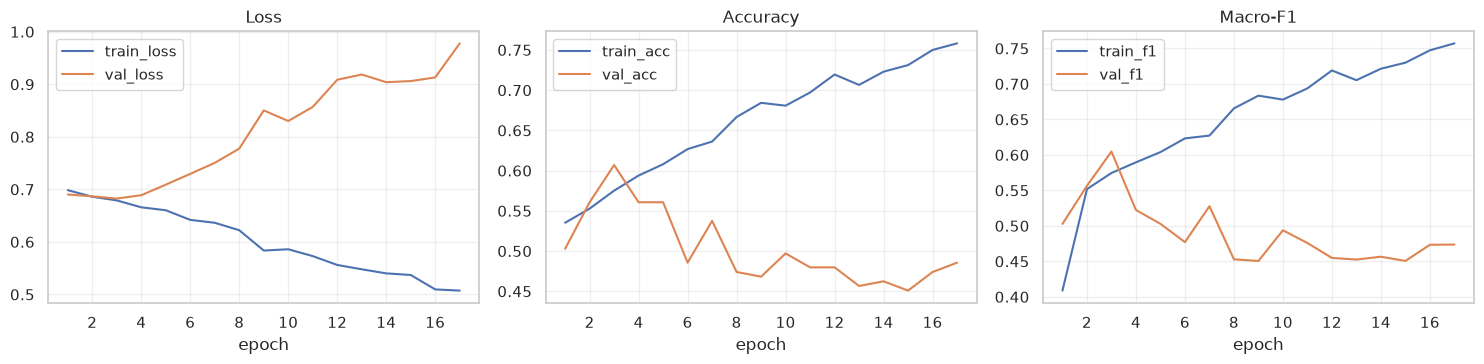

torch.Size([32, 200, 58]) torch.Size([32, 200]) torch.bool | use_mask = True


In [34]:
exp = Experiment(cfg)
result = exp.run(data)
TrainingPlots.curves(result.history)

# sanity: batches must carry the mask
x, y, i, m = next(iter(result.loaders["val"]))
print(x.shape, m.shape, m.dtype, "| use_mask =", cfg.use_mask)

## Evaluate
Train / val / test, plus accuracy by fraction of valid face frames (where the visual stream is reliable).

,accuracy,balanced_acc,f1_macro,precision_lie,recall_lie,auc
train,0.5915,0.5996,0.5914,0.6649,0.5203,0.6546
val,0.6069,0.6054,0.6047,0.6484,0.6211,0.5934
test,0.4940,0.4940,0.4932,0.5357,0.4945,0.5116


,pred Truth,pred Lie
true Truth,46,32
true Lie,36,59


,pred Truth,pred Lie
true Truth,38,39
true Lie,46,45


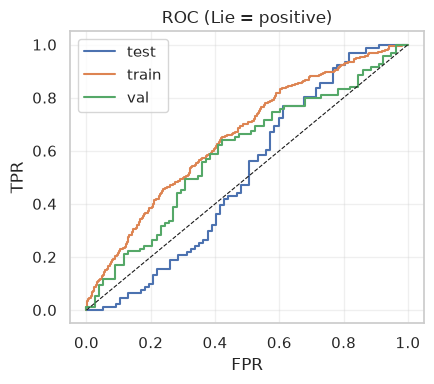

In [35]:
tag = f"{cfg.rnn_type}_{'mask' if cfg.use_mask else 'nomask'}"
display(result.metrics)
for split in ["val", "test"]:
    display(Evaluator.confusion(result.predictions, split))
EvalPlots.roc(result.predictions)

result.predictions.to_csv(f"{cfg.output_dir}/predictions_{tag}_seed{result.seed}.csv", index=False)
result.metrics.to_csv(f"{cfg.output_dir}/metrics_{tag}_seed{result.seed}.csv")

In [36]:
display(Evaluator.per_speaker(result.predictions, "test"))
display(Evaluator.by_validity(result.predictions, "test"))
display(result.predictions.query("split == 'test' and not correct").head(20))

,videos,accuracy
speaker,,
Chris Addison,2,0.000
Catherine,3,0.000
John Barrowman,3,0.000
Greg Rutherford,1,0.000
Ronni Ancona,1,0.000
Sanjeev Bhaskar OBE,3,0.000
Randy_Mills,1,0.000
Miles,5,0.000
Wendy Richard,1,0.000


,videos,accuracy
valid_bin,,
"(0.75, 1.0]",168,0.494


,split,video_id,speaker,label,pred,p_lie,correct,valid_frac
1026,test,deception/DOLOS/Male/Lee Mack/BRI_WILTY_EP61_l...,Lee Mack,Lie,Truth,0.475535,False,1.000
1031,test,truth/DOLOS/Male/John Barrowman/LS_WILTY_EP2_t...,John Barrowman,Truth,Lie,0.521338,False,1.000
1033,test,truth/DOLOS/Male/Lee Mack/AN_WILTY_EP25_truth6...,Lee Mack,Truth,Lie,0.532804,False,1.000
1037,test,deception/DOLOS/Male/Lee Mack/LS_WILTY_EP7_lie...,Lee Mack,Lie,Truth,0.492559,False,1.000
1039,test,deception/DOLOS/Male/Lee Mack/AN_WILTY_EP16_li...,Lee Mack,Lie,Truth,0.417972,False,0.960
1040,test,deception/DOLOS/Female/Sarah Millican/BRI_WILT...,Sarah Millican,Lie,Truth,0.488137,False,1.000
1042,test,deception/DOLOS/Male/Lee Mack/LS_WILTY_EP9_lie...,Lee Mack,Lie,Truth,0.497272,False,1.000
1044,test,deception/DOLOS/Male/Terry Christian/AN_WILTY_...,Terry Christian,Lie,Truth,0.479511,False,1.000
1047,test,truth/DOLOS/Male/Lee Mack/LS_WILTY_EP4_truth6.mp4,Lee Mack,Truth,Lie,0.545014,False,0.945
1048,test,truth/DOLOS/Male/Bradley/YW_WILTY_EP54_truth7.mp4,Bradley,Truth,Lie,0.516493,False,1.000


## Robustness: repeat over seeds
Each seed draws a new speaker split, so this measures split variance as well as init variance.

In [37]:
SEEDS = [0, 1, 2, 3, 4]
sweep = exp.run_seeds(data, seeds=SEEDS)
metric_cols = ["accuracy", "balanced_acc", "f1_macro", "auc"]
display(sweep.groupby("split")[metric_cols].agg(["mean", "std"]).round(3))
EvalPlots.seed_sweep(sweep, "accuracy")
sweep.to_csv(f"{cfg.output_dir}/seed_sweep_{tag}.csv")


=== seed 0 ===
ep   1 | loss 0.694/0.703 | acc 0.478/0.467 | val F1 0.467 (best 0.467 @ 1)
ep   5 | loss 0.652/0.782 | acc 0.618/0.533 | val F1 0.510 (best 0.510 @ 5)
ep  10 | loss 0.604/0.832 | acc 0.655/0.462 | val F1 0.459 (best 0.510 @ 5)
ep  15 | loss 0.518/1.045 | acc 0.747/0.515 | val F1 0.502 (best 0.510 @ 5)


KeyboardInterrupt: 